In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


# Load dataset
df = pd.read_csv('/content/sample_data/Loan_Dataset_Expanded (1).csv')

# ---------------------------
# 1. Basic EDA
# ---------------------------
print(df.shape)
print(df.describe())
print(df.head())
print("\n")
print(df.isnull().sum())

(2500, 13)
       ApplicantIncome  CoapplicantIncome   LoanAmount  Loan_Amount_Term  \
count       2500.00000        2500.000000  2397.000000       2453.000000   
mean        5405.19080        1749.885968   146.684189        343.841826   
std         6081.27067        3483.412587    88.592118         63.227142   
min          139.00000           0.000000     9.000000         12.000000   
25%         2857.50000           0.000000    94.000000        360.000000   
50%         3813.50000        1280.500000   127.000000        360.000000   
75%         5751.25000        2370.250000   173.000000        360.000000   
max        81000.00000       43367.000000   750.000000        480.000000   

       Credit_History  
count     2295.000000  
mean         0.850980  
std          0.356185  
min          0.000000  
25%          1.000000  
50%          1.000000  
75%          1.000000  
max          1.000000  
    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001581   Male 

In [ ]:
# ---------------------------
# 2. Handle Missing Values
# ---------------------------
df['LoanAmount'].fillna(df['LoanAmount'].median(), inplace=True)
df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mean(), inplace=True)
df['Credit_History'].fillna(df['Credit_History'].mode()[0], inplace=True)

for col in ['Gender','Married','Dependents','Self_Employed']:
    df[col].fillna(df[col].mode()[0], inplace=True)

print('\nNumber of people who took loan by gender')
print(df['Gender'].value_counts())
#sns.countplot(x='Gender',data = df, palette='Set1')

print('\nNumber of people who took loan by Married')
print(df['Married'].value_counts())
#sns.countplot(x='Married',data = df, palette='Set1')

print('\nNumber of people who took loan by Education')
print(df['Education'].value_counts())
#sns.countplot(x='Education',data = df, palette='Set1')

print('\nNumber of people who took loan by Dependents')
print(df['Dependents'].value_counts())

print('\nNumber of people who took loan by Self_employment')
print(df['Self_Employed'].value_counts())


# ---------------------------
# 3. Encoding (needed for baseline too)
# ---------------------------
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])


Number of people who took loan by gender
Gender
Male      2035
Female     465
Name: count, dtype: int64

Number of people who took loan by Married
Married
Yes    1616
No      884
Name: count, dtype: int64

Number of people who took loan by Education
Education
Graduate        1964
Not Graduate     536
Name: count, dtype: int64

Number of people who took loan by Dependents
Dependents
0     1558
1      396
2      374
3+     172
Name: count, dtype: int64

Number of people who took loan by Self_employment
Self_Employed
No     2167
Yes     333
Name: count, dtype: int64



=== BASELINE MODEL ===
Accuracy: 0.7792
              precision    recall  f1-score   support

           0       0.94      0.36      0.52       207
           1       0.76      0.99      0.86       418

    accuracy                           0.78       625
   macro avg       0.85      0.67      0.69       625
weighted avg       0.82      0.78      0.74       625



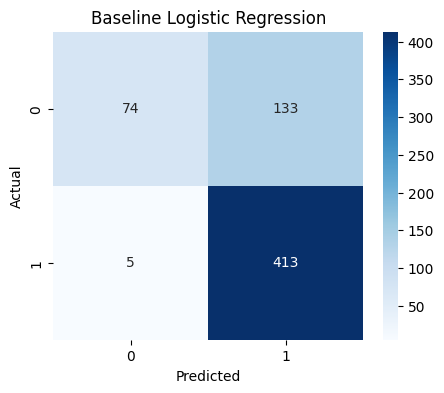

In [ ]:
# ---------------------------
# 4. BASELINE MODEL (BASE DATA)
# ---------------------------
X_base = df.drop('Loan_Status', axis=1)
y_base = df['Loan_Status']

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_base, y_base, test_size=0.25, random_state=42
)

lr_base = LogisticRegression()
lr_base.fit(Xb_train, yb_train)
yb_pred = lr_base.predict(Xb_test)

print("\n=== BASELINE MODEL ===")
print("Accuracy:", accuracy_score(yb_test, yb_pred))
print(classification_report(yb_test, yb_pred))

#Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

plot_confusion_matrix(yb_test, yb_pred, "Baseline Logistic Regression")

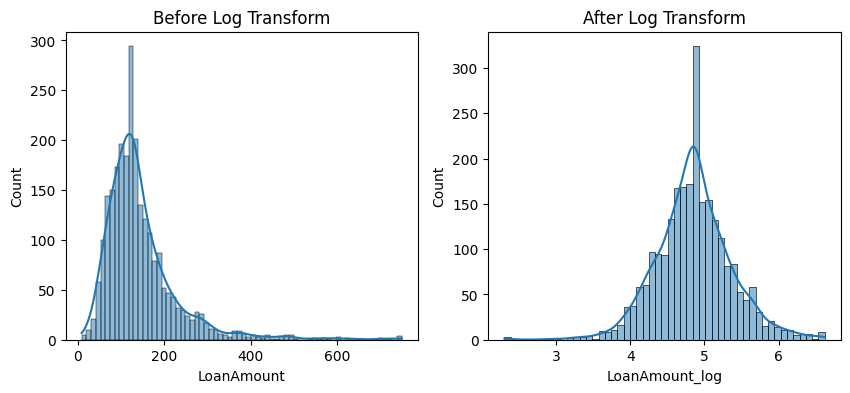

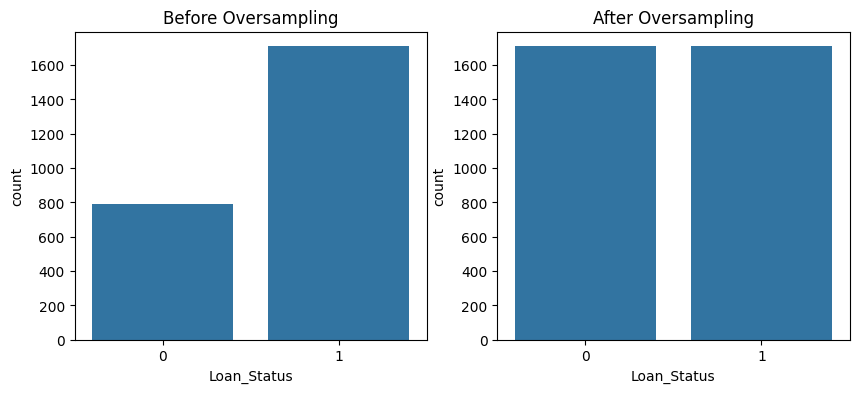

In [ ]:
# ---------------------------
# 5. Feature Engineering
# ---------------------------
df['Total_Income'] = df['ApplicantIncome'] + df['CoapplicantIncome']

# ---------------------------
# 6. Log Transformation
# ---------------------------
df['LoanAmount_log'] = np.log(df['LoanAmount'] + 1)
df['Total_Income_log'] = np.log(df['Total_Income'] + 1)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
sns.histplot(df['LoanAmount'], kde=True)
plt.title("Before Log Transform")

plt.subplot(1,2,2)
sns.histplot(df['LoanAmount_log'], kde=True)
plt.title("After Log Transform")

plt.show()

# ---------------------------
# Keep a copy for visualization
# ---------------------------

df_visual = df.copy()

# Drop original skewed columns
df.drop(columns=['LoanAmount','Total_Income'], inplace=True)


# ---------------------------
# 7. Drop unnecessary columns
# ---------------------------

df.drop(
    columns=[
        'Loan_ID',
        'ApplicantIncome',
        'CoapplicantIncome',
        'LoanAmount',
        'Total_Income'
    ],
    inplace=True,
    errors='ignore'
)

# ---------------------------
# 8. Final dataset split
# ---------------------------
X = df.drop('Loan_Status', axis=1)
y = df['Loan_Status']

# ---------------------------
# 9. Handle imbalance
# ---------------------------
from imblearn.over_sampling import RandomOverSampler

# Before vs After Oversampling
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
sns.countplot(x=y)
plt.title("Before Oversampling")

ros = RandomOverSampler(random_state=42)
X_res, y_res = ros.fit_resample(X, y)

plt.subplot(1,2,2)
sns.countplot(x=y_res)
plt.title("After Oversampling")

plt.show()

In [ ]:
# ---------------------------
# 10. Train-test split
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_res, y_res, test_size=0.25, random_state=42
)



=== FINAL MODELS ===

Logistic Regression:
Accuracy: 0.704093567251462
              precision    recall  f1-score   support

           0       0.83      0.50      0.62       419
           1       0.65      0.90      0.76       436

    accuracy                           0.70       855
   macro avg       0.74      0.70      0.69       855
weighted avg       0.74      0.70      0.69       855



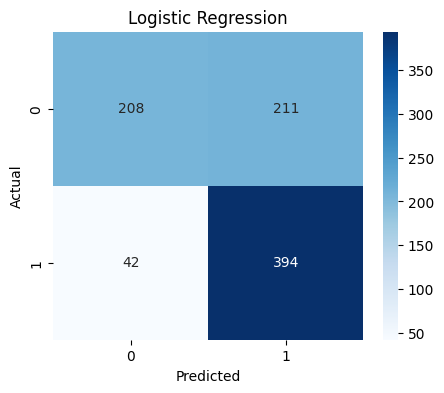


Decision Tree:
Accuracy: 0.8187134502923976
              precision    recall  f1-score   support

           0       0.77      0.91      0.83       419
           1       0.89      0.73      0.80       436

    accuracy                           0.82       855
   macro avg       0.83      0.82      0.82       855
weighted avg       0.83      0.82      0.82       855



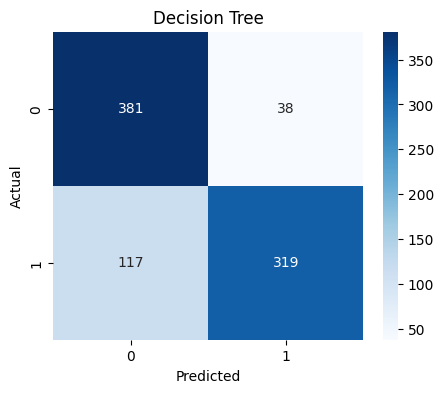


Random Forest:
Accuracy: 0.8725146198830409
              precision    recall  f1-score   support

           0       0.85      0.90      0.87       419
           1       0.90      0.85      0.87       436

    accuracy                           0.87       855
   macro avg       0.87      0.87      0.87       855
weighted avg       0.87      0.87      0.87       855



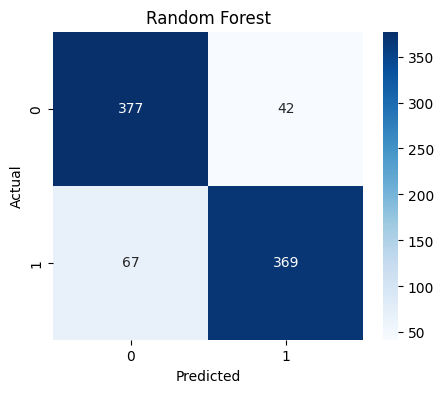

In [ ]:
# ---------------------------
# 11. Models
# ---------------------------
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Logistic Regression
lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# ---------------------------
# 12. Evaluation
# ---------------------------
print("\n=== FINAL MODELS ===")

print("\nLogistic Regression:")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))
plot_confusion_matrix(y_test, y_pred_lr, "Logistic Regression")

print("\nDecision Tree:")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))
plot_confusion_matrix(y_test, y_pred_dt, "Decision Tree")

print("\nRandom Forest:")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
plot_confusion_matrix(y_test, y_pred_rf, "Random Forest")

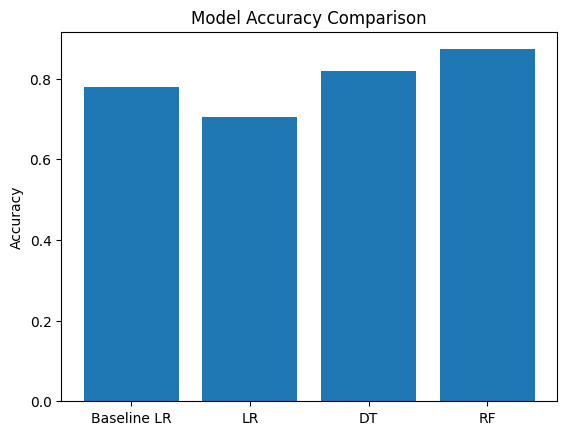

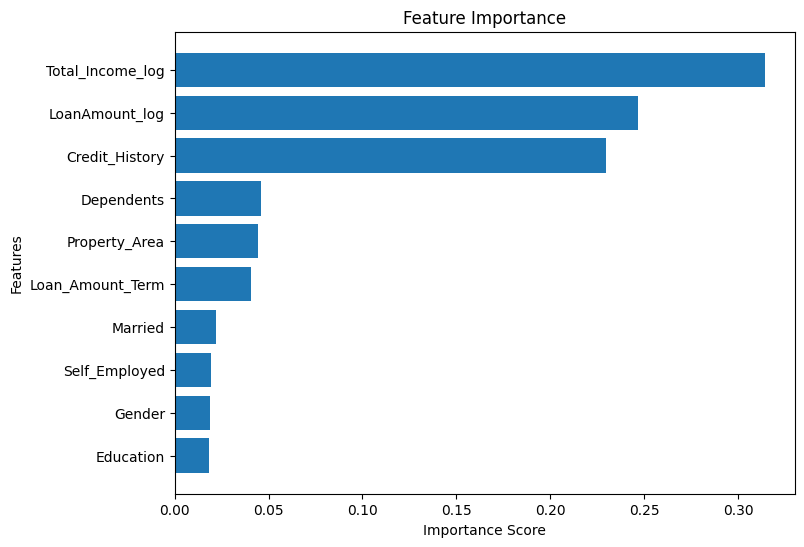

In [ ]:
# ---------------------------
# 14. Model Comparison Plot (Optional but Strong)
# ---------------------------
models = ['Baseline LR', 'LR', 'DT', 'RF']
accuracies = [
    accuracy_score(yb_test, yb_pred),
    accuracy_score(y_test, y_pred_lr),
    accuracy_score(y_test, y_pred_dt),
    accuracy_score(y_test, y_pred_rf)
]

plt.bar(models, accuracies)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.show()

# ---------------------------
# 13. Feature Importance
# ---------------------------
importances = rf.feature_importances_
features = X.columns

indices = np.argsort(importances)

plt.figure(figsize=(8,6))
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), features[indices])
plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

BUSINESS INSIGHTS & RELATIONSHIP ANALYSIS

Top Features Influencing Loan Approval

            Feature  Importance
0  Total_Income_log    0.314548
1    LoanAmount_log    0.246515
2    Credit_History    0.229934
3        Dependents    0.045712
4     Property_Area    0.044518
5  Loan_Amount_Term    0.040404
6           Married    0.021884
7     Self_Employed    0.019432
8            Gender    0.018759
9         Education    0.018295


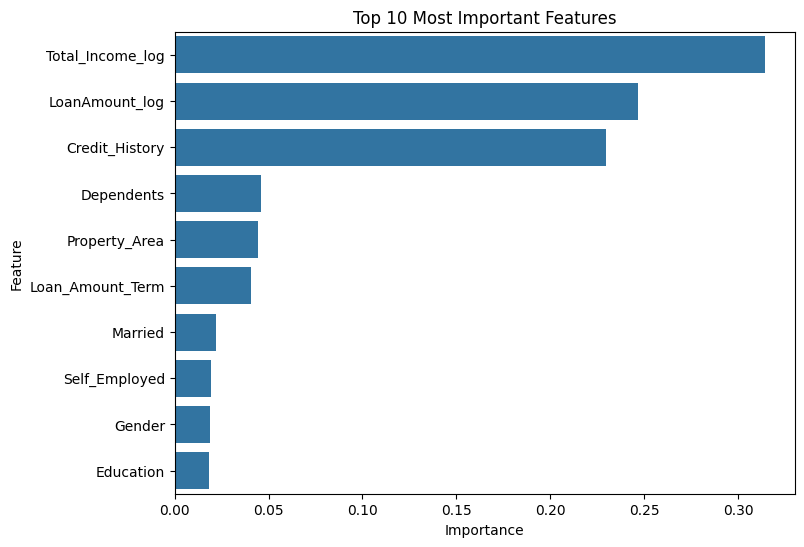

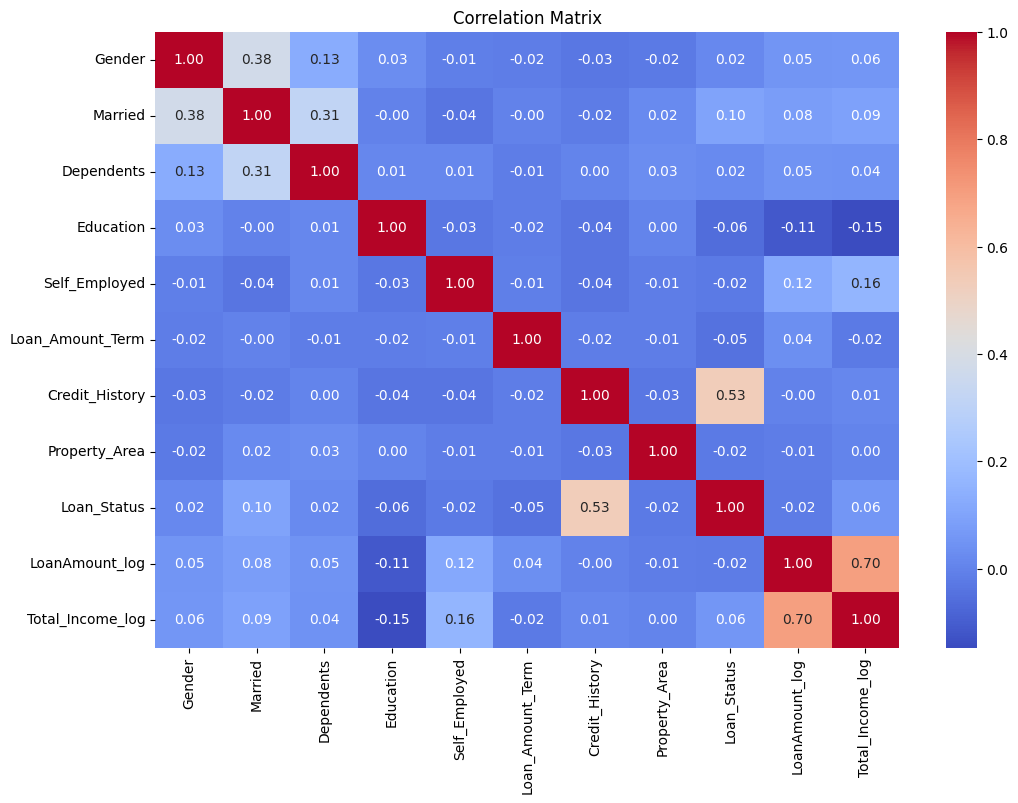

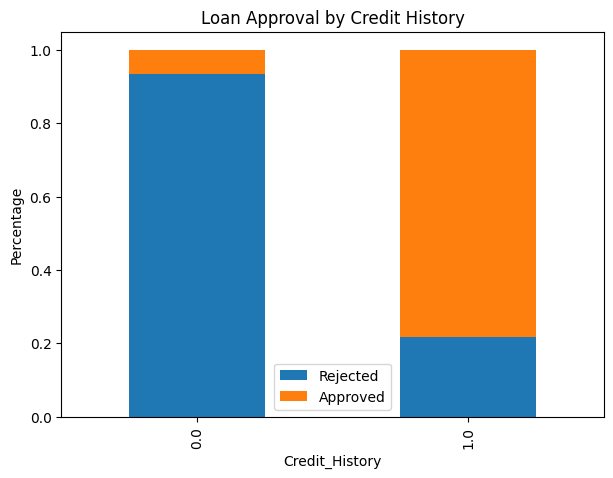


Loan Approval by Credit History
Loan_Status            0         1
Credit_History                    
0.0             0.935673  0.064327
1.0             0.218258  0.781742


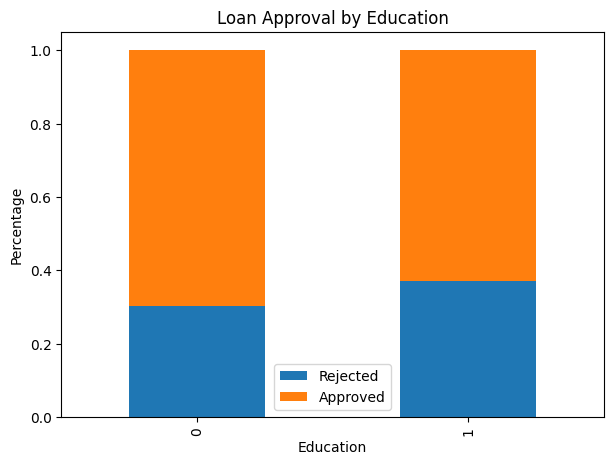


Loan Approval by Education
Loan_Status         0         1
Education                      
0            0.301935  0.698065
1            0.369403  0.630597


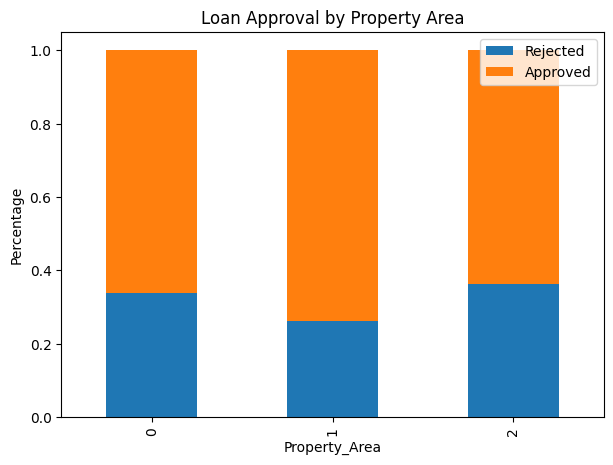


Loan Approval by Property Area
Loan_Status           0         1
Property_Area                    
0              0.338776  0.661224
1              0.260231  0.739769
2              0.362069  0.637931


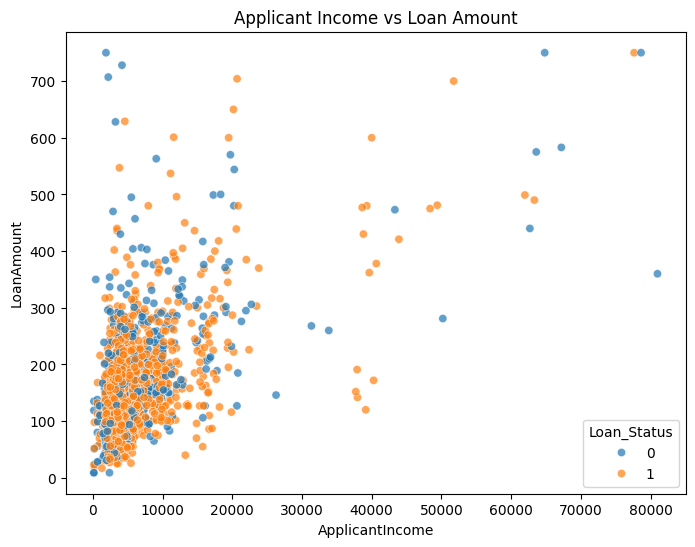

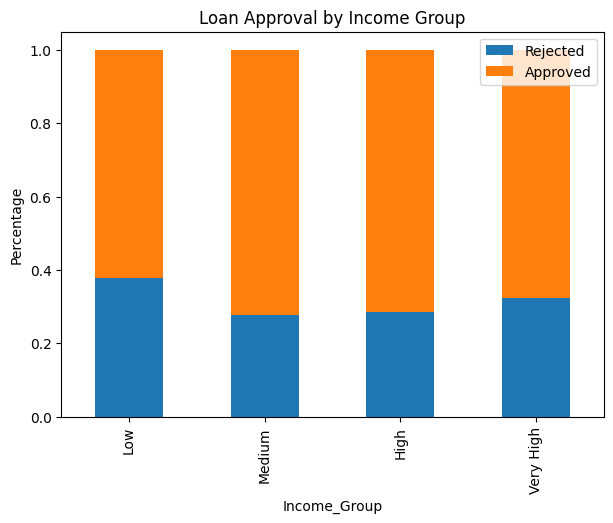


Loan Approval by Income Group
Loan_Status        0       1
Income_Group                
Low           0.3792  0.6208
Medium        0.2768  0.7232
High          0.2848  0.7152
Very High     0.3248  0.6752


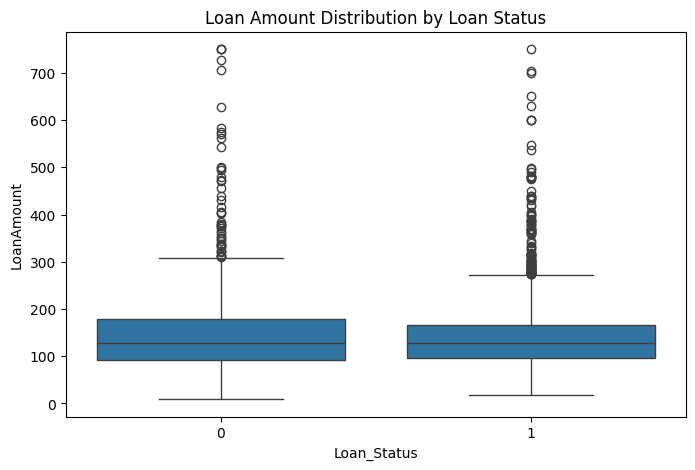

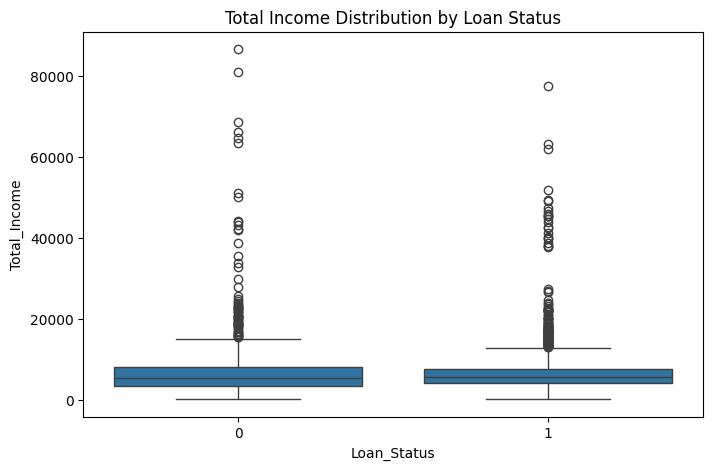


Overall Loan Approval Percentage
Loan_Status
1    68.36
0    31.64
Name: proportion, dtype: float64

Model Comparison
                 Model  Accuracy
0          Baseline LR  0.779200
1  Logistic Regression  0.704094
2        Decision Tree  0.818713
3        Random Forest  0.872515

Best Model
Model       Random Forest
Accuracy         0.872515
Name: 3, dtype: object

Top Correlations with Loan Status
Loan_Status         1.000000
Credit_History      0.530090
Married             0.095892
Total_Income_log    0.056618
Dependents          0.018877
Gender              0.015194
LoanAmount_log     -0.021188
Self_Employed      -0.021867
Property_Area      -0.022581
Loan_Amount_Term   -0.047459
Education          -0.059538
Name: Loan_Status, dtype: float64


ACTIONABLE BUSINESS INSIGHTS

1. The Random Forest model achieved the highest prediction accuracy (87.25%), making it the most suitable model among those evaluated for loan approval prediction.

2. Total Household Income (log transformed),

In [ ]:
# ==========================================================
# BUSINESS INSIGHTS & RELATIONSHIP ANALYSIS
# ==========================================================

print("="*70)
print("BUSINESS INSIGHTS & RELATIONSHIP ANALYSIS")
print("="*70)

# ---------------------------
# 1. Feature Importance Table
# ---------------------------

importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\nTop Features Influencing Loan Approval\n")
print(importance_df)

plt.figure(figsize=(8,6))
sns.barplot(
    data=importance_df.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Most Important Features")
plt.show()

# ---------------------------
# 2. Correlation Heatmap
# ---------------------------

plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

# ---------------------------
# 3. Loan Approval by Credit History
# ---------------------------

credit_table = pd.crosstab(
    df['Credit_History'],
    df['Loan_Status'],
    normalize='index'
)

credit_table.plot(
    kind='bar',
    stacked=True,
    figsize=(7,5)
)

plt.title("Loan Approval by Credit History")
plt.ylabel("Percentage")
plt.legend(['Rejected','Approved'])
plt.show()

print("\nLoan Approval by Credit History")
print(credit_table)

# ---------------------------
# 4. Loan Approval by Education
# ---------------------------

education_table = pd.crosstab(
    df['Education'],
    df['Loan_Status'],
    normalize='index'
)

education_table.plot(
    kind='bar',
    stacked=True,
    figsize=(7,5)
)

plt.title("Loan Approval by Education")
plt.ylabel("Percentage")
plt.legend(['Rejected','Approved'])
plt.show()

print("\nLoan Approval by Education")
print(education_table)

# ---------------------------
# 5. Loan Approval by Property Area
# ---------------------------

property_table = pd.crosstab(
    df['Property_Area'],
    df['Loan_Status'],
    normalize='index'
)

property_table.plot(
    kind='bar',
    stacked=True,
    figsize=(7,5)
)

plt.title("Loan Approval by Property Area")
plt.ylabel("Percentage")
plt.legend(['Rejected','Approved'])
plt.show()

print("\nLoan Approval by Property Area")
print(property_table)

# ---------------------------
# 6. Income vs Loan Amount
# ---------------------------

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_visual,
    x='ApplicantIncome',
    y='LoanAmount',
    hue='Loan_Status',
    alpha=0.7
)

plt.title("Applicant Income vs Loan Amount")
plt.show()

# ---------------------------
# 7. Income Group Analysis
# ---------------------------

df_visual['Income_Group'] = pd.qcut(
    df_visual['ApplicantIncome'],
    4,
    labels=[
        'Low',
        'Medium',
        'High',
        'Very High'
    ]
)

income_table = pd.crosstab(
    df_visual['Income_Group'],
    df_visual['Loan_Status'],
    normalize='index'
)

income_table.plot(
    kind='bar',
    stacked=True,
    figsize=(7,5)
)

plt.title("Loan Approval by Income Group")
plt.ylabel("Percentage")
plt.legend(['Rejected','Approved'])
plt.show()

print("\nLoan Approval by Income Group")
print(income_table)

# ---------------------------
# 8. Loan Amount Distribution
# ---------------------------

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_visual,
    x='Loan_Status',
    y='LoanAmount'
)

plt.title("Loan Amount Distribution by Loan Status")
plt.show()

# ---------------------------
# 9. Total Income Distribution
# ---------------------------

if 'Total_Income' not in df_visual.columns:
    df_visual['Total_Income'] = (
        df_visual['ApplicantIncome'] +
        df_visual['CoapplicantIncome']
    )

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_visual,
    x='Loan_Status',
    y='Total_Income'
)

plt.title("Total Income Distribution by Loan Status")
plt.show()

# ---------------------------
# 10. Approval Percentage
# ---------------------------

approval_rate = (
    df['Loan_Status'].value_counts(normalize=True) * 100
)

print("\nOverall Loan Approval Percentage")

print(approval_rate)

# ---------------------------
# 11. Model Comparison Table
# ---------------------------

comparison = pd.DataFrame({

    "Model":[
        "Baseline LR",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy":[
        accuracy_score(yb_test,yb_pred),
        accuracy_score(y_test,y_pred_lr),
        accuracy_score(y_test,y_pred_dt),
        accuracy_score(y_test,y_pred_rf)
    ]

})

print("\nModel Comparison")

print(comparison)

best_model = comparison.iloc[
    comparison['Accuracy'].idxmax()
]

print("\nBest Model")

print(best_model)

# ---------------------------
# 12. Top Correlations with Loan Status
# ---------------------------

print("\nTop Correlations with Loan Status")

corr = df.corr(numeric_only=True)['Loan_Status'].sort_values(
    ascending=False
)

print(corr)

# ---------------------------
# 13. Automatic Business Insights
# ---------------------------

# ---------------------------
# 13. Actionable Business Insights
# ---------------------------

print("\n")
print("="*70)
print("ACTIONABLE BUSINESS INSIGHTS")
print("="*70)

print(f"\n1. The Random Forest model achieved the highest prediction accuracy ({best_model['Accuracy']:.2%}), making it the most suitable model among those evaluated for loan approval prediction.")

print("\n2. Total Household Income (log transformed), Loan Amount (log transformed), and Credit History together account for nearly 79% of the model's overall feature importance, indicating that financial factors dominate loan approval decisions.")

print("\n3. Credit History is one of the strongest predictors of loan approval.")
print("   • Applicants with positive credit history have an approval rate of 78.17%.")
print("   • Applicants with poor credit history have an approval rate of only 6.43%.")
print("   This highlights previous repayment behaviour as a key screening criterion.")

print("\n4. Applicants with graduate-level education have a slightly higher approval rate (69.81%) than non-graduates (63.06%).")
print("   However, the relatively small difference indicates that education has only a limited influence compared to financial variables.")

print("\n5. Semi-urban applicants show the highest approval rate (73.98%), compared with urban (66.12%) and rural applicants (63.79%).")
print("   Although location has some influence, its impact is considerably smaller than credit history and financial capacity.")

print("\n6. Loan approval improves substantially from the Low Income group (62.08%) to the Medium Income group (72.32%).")
print("   Beyond this level, approval rates remain relatively stable, suggesting that income above a reasonable threshold provides limited additional predictive value.")

print("\n7. Correlation analysis shows that Credit History has the strongest positive relationship with Loan Status (Correlation = 0.53).")
print("   All other variables exhibit relatively weak correlations, indicating that loan approval depends on multiple interacting factors rather than a single demographic characteristic.")

print("\n8. The superior performance of Random Forest suggests that loan approval decisions involve nonlinear relationships between applicant characteristics that are not fully captured by linear models such as Logistic Regression.")

print("\n9. Business Recommendations:")
print("   • Prioritize applicants with strong credit history during preliminary screening.")
print("   • Focus on repayment capacity using household income and requested loan amount.")
print("   • Use demographic attributes such as gender and education only as supplementary information.")
print("   • Consider deploying Random Forest as a decision-support model to improve consistency and accuracy in loan approval.")

print("\n10. Overall Conclusion:")
print("    The analysis demonstrates that loan approval is driven primarily by objective financial indicators and previous credit behaviour rather than demographic characteristics. Incorporating machine learning models such as Random Forest can assist financial institutions in making faster, more consistent, and data-driven lending decisions while reducing subjectivity in the approval process.")

print("="*70)
print("END OF ANALYSIS")
print("="*70)